In [7]:
import pandas as pd
import matplotlib.pyplot as plt
nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")

/tmp/ipykernel_4522/4067298134.py:3: DtypeWarning: Columns (141: ServedActiveDutyInUsArmedForces) have mixed types. Specify dtype option on import or set low_memory=False.
  nhanes=pd.read_csv("https://raw.githubusercontent.com/Psyc3000A/Data/refs/heads/main/nhanes.csv")


In [8]:
children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

<Axes: >

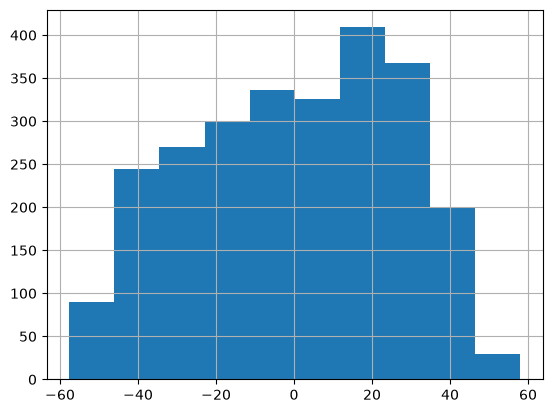

In [9]:
(children["StandingHeightCm"] - children["StandingHeightCm"].mean()).hist()

<Axes: >

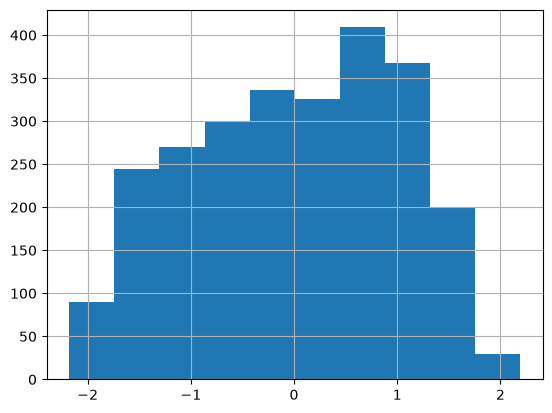

In [10]:
((children["StandingHeightCm"] - children["StandingHeightCm"].mean())/children["StandingHeightCm"].std()).hist()

the first subtracts the mean, so 0 = average height in cm; the second also divides by the SD, which makes it a z-score.

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

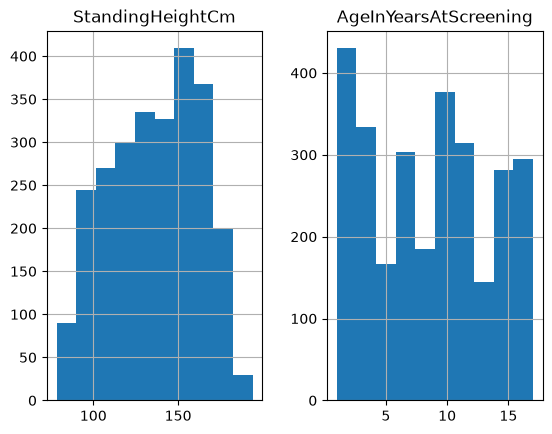

In [11]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].hist()

array([[<Axes: title={'center': 'StandingHeightCm'}>,
        <Axes: title={'center': 'AgeInYearsAtScreening'}>]], dtype=object)

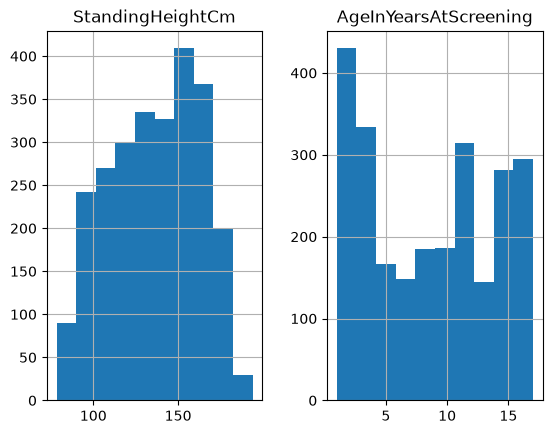

In [12]:
children[["StandingHeightCm","AgeInYearsAtScreening"]].replace([7,9,77,99,777,999,7777,9999], pd.NA).astype("Float64").hist()

The second line treats 7, 9, 77, 99, etc. as missing-value codes and blanks them out. The height histogram barely changes, but in the age histogram two bars drop to about half their size. Those bars contain ages 7 and 9, so real 7- and 9-year-olds were deleted, because for children those numbers are actual ages, not missing codes.

In [13]:
children["AgeInYearsAtScreening"].describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

In [14]:
children["AgeInYearsAtScreening"].dropna().describe()

count    2833.000000
mean        8.513590
std         4.905092
min         1.000000
25%         4.000000
50%         8.000000
75%        13.000000
max        17.000000
Name: AgeInYearsAtScreening, dtype: float64

The two lines give the same results because .describe() already skips missing values automatically, so using .dropna() first doesn’t change anything.

In [15]:
import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)

,names,coef,se,T,pval,r2,adj_r2,CI2.5,CI97.5
0,Intercept,-2.443957,0.568574,-4.298396,0.000017,0.249317,0.249223,-3.558511,-1.329404
1,StandingHeightCm,0.185338,0.003595,51.555402,0.000000,0.249317,0.249223,0.178291,0.192385


<Axes: xlabel='StandingHeightCm', ylabel='BodyMassIndexKgm2'>

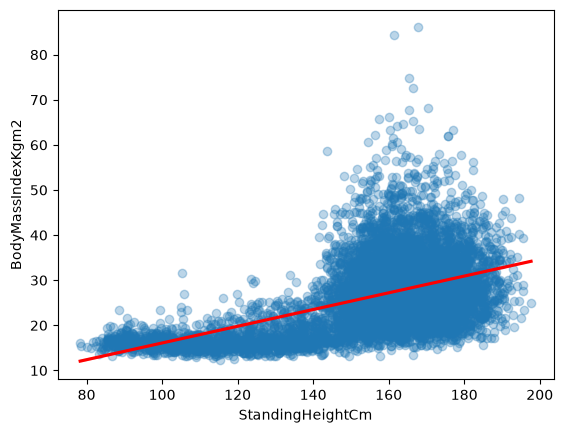

In [18]:

import seaborn as sns
import pingouin as pg
pg.linear_regression(nhanes["StandingHeightCm"], nhanes["BodyMassIndexKgm2"],remove_na=True)
#with vs. without this line:
sns.regplot(data=nhanes,x="StandingHeightCm", y="BodyMassIndexKgm2",scatter_kws={"color": "C0", "alpha": 0.3},line_kws={"color": "red"})

Both lines look at the relationship between height and BMI. The first line gives the results as a table of numbers. The second line shows the same thing as a graph, a scatterplot with a line through it.

/tmp/ipykernel_4522/519482144.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)


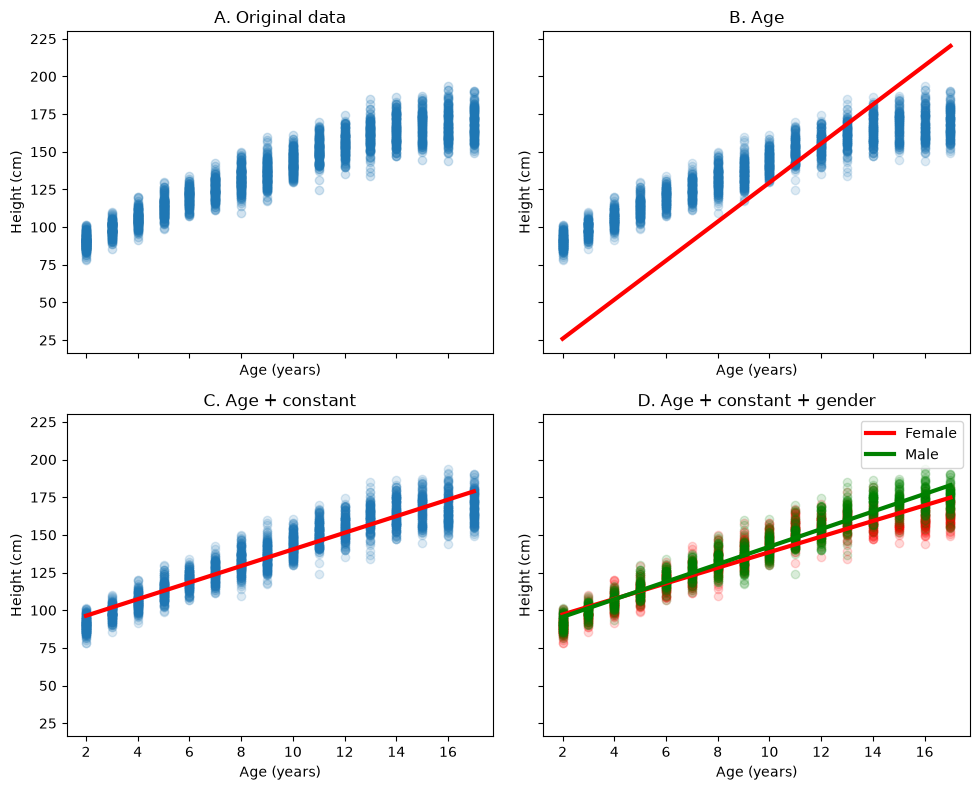

In [24]:
children = nhanes[nhanes["AgeInYearsAtScreening"] < 18]

import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

children["Gender_code"] = (children["Gender"].astype(str).str.lower().isin(["male", "1"])).astype(int)
children = children[["StandingHeightCm", "AgeInYearsAtScreening", "Gender_code"]].dropna()

m_age = LinearRegression(fit_intercept=False).fit(children[["AgeInYearsAtScreening"]],children["StandingHeightCm"])
m_age_const = LinearRegression().fit(children[["AgeInYearsAtScreening"]], children["StandingHeightCm"])
m_full = LinearRegression().fit(children[["AgeInYearsAtScreening", "Gender_code"]],children["StandingHeightCm"])

children = children.sort_values("AgeInYearsAtScreening")
children["pred_age"] = m_age.predict(children[["AgeInYearsAtScreening"]])
children["pred_age_const"] = m_age_const.predict(children[["AgeInYearsAtScreening"]])
children["pred_full"] = m_full.predict(children[["AgeInYearsAtScreening", "Gender_code"]])

children["Age_Gender"] = (children["AgeInYearsAtScreening"] * children["Gender_code"])
m_interaction = LinearRegression().fit(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]],children["StandingHeightCm"])
children["pred_interaction"] = m_interaction.predict(children[["AgeInYearsAtScreening","Gender_code","Age_Gender"]])

fig, ax = plt.subplots(2, 2, figsize=(10, 8), sharex=True, sharey=True)
ax[0,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.2)
ax[0,0].set_title("A. Original data")
ax[0,1].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[0,1].plot(children["AgeInYearsAtScreening"], children["pred_age"], color="red", lw=3)
ax[0,1].set_title("B. Age")
ax[1,0].scatter(children["AgeInYearsAtScreening"], children["StandingHeightCm"], alpha=.15)
ax[1,0].plot(children["AgeInYearsAtScreening"], children["pred_age_const"], color="red", lw=3)
ax[1,0].set_title("C. Age + constant")
for g, color, label in [(0, "red", "Female"),(1, "green", "Male")]:
    tmp = children[children["Gender_code"] == g].sort_values("AgeInYearsAtScreening")
    ax[1,1].scatter(tmp["AgeInYearsAtScreening"],tmp["StandingHeightCm"],alpha=.15,color=color)
    ax[1,1].plot(tmp["AgeInYearsAtScreening"],tmp["pred_interaction"],color=color,lw=3,label=label)
ax[1,1].legend()
ax[1,1].set_title("D. Age + constant + gender")
for a in ax.ravel():
    a.set_xlabel("Age (years)")
    a.set_ylabel("Height (cm)")
plt.tight_layout()
plt.show()

I ran into some trouble getting the Q3 code to work. The version on the assignment page is cut off at the end, so I used the full version from the class3 notebook instead. It also gave me an error when I ran it a second time, so I added children = nhanes[nhanes["AgeInYearsAtScreening"] < 18] at the top to fix that. Just flagging in case other students run into the same issue.

The four graphs show kids’ height by age, each with a different model. A shows just the data with no model. B uses age only, but the line has to start at zero, so it fits badly: too low for young kids and too high for teens. C adds a constant (the starting point), so the line fits the data much better. D has separate lines for girls and boys. They’re very similar for younger kids, but boys get a little taller in the older ages.